# B11. Đánh giá trên tập kiểm tra

Chấm ba mô hình **một lần duy nhất** trên tập kiểm tra (61.503 hồ sơ, 20% `application_train`, `ml/data/split.csv`), tập chưa được dùng ở bất kỳ bước nào trước.
Mọi lựa chọn đã cố định trước khi chạy notebook này: đặc trưng (B6), tiền xử lý (B7), siêu tham số và số cây (B8, `tham_so.json`), bộ hiệu chỉnh (B9, `hieu_chinh.json`), ngưỡng (B10, `nguong.json`).
Mỗi mô hình học lại một lần trên **toàn bộ 246.008 hồ sơ train**, dự đoán tập kiểm tra một lần; sau đó chỉ tính metric trên các dự đoán đã lưu.
Đầu ra: `ml/data/du_doan_test.parquet` (xác suất gốc và đã hiệu chỉnh của 3 mô hình), `ml/models/<mô hình>.joblib` (mô hình được chọn cho B12, B13).

## 0. Nguồn đã tra và cách áp dụng

| Nguồn | Nội dung | Áp dụng |
|---|---|---|
| Hastie, Tibshirani, Friedman (2009), *The Elements of Statistical Learning*, mục 7.2 | Tách ba phần: học, chọn mô hình, đánh giá; tập kiểm tra chỉ dùng ở cuối, dùng lặp lại để chọn thì sai số kiểm tra đánh giá thấp sai số thật | Test chạm một lần, sau khi mọi tham số đã đóng băng; không đổi gì sau khi thấy kết quả |
| Cawley, Talbot (2010), JMLR 11 | Điểm CV của bộ tham số thắng lạc quan do chọn lựa | So AUC CV (B8) với AUC test để đo mức lạc quan |
| Hanley, McNeil (1982), *Radiology* 143; DeLong và cộng sự (1988), *Biometrics* 44 | AUC = xác suất một hồ sơ nhãn 1 lấy ngẫu nhiên có điểm cao hơn một hồ sơ nhãn 0 lấy ngẫu nhiên (thống kê Mann–Whitney); AUC của hai mô hình trên cùng hồ sơ tương quan nên phải so theo cặp | Tính AUC theo hạng (cách Mann–Whitney) trong bootstrap, kiểm lại bằng `roc_auc_score`; hiệu AUC so theo cặp trên cùng mẫu lặp |
| pROC (Robin và cộng sự 2011, *BMC Bioinformatics* 12:77), tài liệu `roc.test`, `ci.auc`; Carpenter, Bithell (2000), *Statistics in Medicine* 19 | Bootstrap không tham số, khoảng tin cậy phân vị; mặc định **phân tầng**: mỗi mẫu lặp giữ đúng số hồ sơ nhãn 1 và nhãn 0 như mẫu gốc (an toàn khi lệch lớp) | **Bootstrap cặp phân tầng, 10.000 lần, seed 42**, CI phân vị 95% cho AUC từng mô hình và cho hiệu AUC giữa hai mô hình (cùng số lần, seed như phần RAG) |
| Thomas, Edelman, Crook (2002), *Credit Scoring and Its Applications*; Siddiqi (2017), *Intelligent Credit Scoring* | Thống kê KS = khoảng cách lớn nhất giữa hai hàm phân phối tích lũy của điểm ở nhóm tốt và nhóm xấu = max(TPR − FPR) trên đường ROC; chỉ số phân biệt thông dụng trong chấm điểm tín dụng | KS tính từ `roc_curve` trên xác suất gốc |
| Saito, Rehmsmeier (2015), *PLOS ONE* 10(3) | Khi lớp dương hiếm, đường precision–recall cho thông tin mà ROC che đi; mốc ngẫu nhiên của PR-AUC là tỷ lệ lớp dương | Báo cáo PR-AUC (`average_precision_score`) kèm mốc 8,07% |
| Van Calster và cộng sự (2019), *BMC Medicine* 17:230; Steyerberg (2019), *Clinical Prediction Models* | Kiểm tra độ khớp trên dữ liệu chưa thấy: chênh trung bình, hệ số góc, đường cong | Lặp lại đúng các phép đo của B9 trên test bằng xác suất đã hiệu chỉnh |
| Lời giải Kaggle Home Credit: hạng 2 (ikiri_DS, private 0,80561), hạng 5 (deepsense.ai), hạng 17 (NoxMoon, private 0,80265) | Mốc AUC trên tập test của cuộc thi với hàng nghìn đặc trưng và ghép nhiều mô hình | Chỉ để đặt kết quả vào bối cảnh: khác tập kiểm tra (test của cuộc thi, không phải 20% train), khác số đặc trưng, nên không so trực tiếp |

Không áp dụng: kiểm định DeLong hay giá trị p (chỉ dùng CI bootstrap, như phần RAG), Accuracy (B1), chọn lại ngưỡng hay bộ hiệu chỉnh trên test.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.calibration import calibration_curve
from sklearn.compose import make_column_transformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, f1_score, log_loss,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA, FIG_DIR = ROOT / "ml" / "data", ROOT / "ml" / "hinh"
INK, MUTED, BLUE, ORANGE, GRID = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834", "#e4e3df"
SEED = 42
MO_HINH = ["LR", "RF", "LGBM"]
TEN = {"LR": "Hồi quy logistic", "RF": "Rừng ngẫu nhiên", "LGBM": "LightGBM"}
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

f = pd.read_parquet(DATA / "features.parquet").merge(pd.read_csv(DATA / "split.csv"), on="SK_ID_CURR")
tham_so = json.loads((DATA / "tham_so.json").read_text())
hieu_chinh = json.loads((DATA / "hieu_chinh.json").read_text())
nguong = json.loads((DATA / "nguong.json").read_text())
oof = pd.read_parquet(DATA / "oof.parquet")

tr, te = f[f.tap == "train"], f[f.tap == "test"]
X_tr, y_tr = tr.drop(columns=["SK_ID_CURR", "TARGET", "tap"]), tr.TARGET.to_numpy()
X_te, y_te = te.drop(columns=["SK_ID_CURR", "TARGET", "tap"]), te.TARGET.to_numpy()
CHU = X_tr.select_dtypes(exclude="number").columns.tolist()
SO = [c for c in X_tr.columns if c not in CHU]
assert not set(tr.SK_ID_CURR) & set(te.SK_ID_CURR) and set(oof.SK_ID_CURR) == set(tr.SK_ID_CURR)
print(f"Train {len(tr):,} (TARGET=1 {y_tr.mean():.4%}), test {len(te):,} (TARGET=1 {y_te.mean():.4%}); {len(SO)} cột số, {len(CHU)} cột chữ")

Train 246,008 (TARGET=1 8.0729%), test 61,503 (TARGET=1 8.0728%); 109 cột số, 15 cột chữ


## 1. Luật đánh giá (đặt trước khi chạy)

- **Mô hình cuối:** tiền xử lý và mô hình fit trên toàn bộ train bằng đúng tham số `tham_so.json`; LightGBM dùng 971 cây cố định (trung bình số cây dừng sớm ở B8), không dừng sớm.
- **Hai thang xác suất** (như B9 đã ghi): ROC-AUC, PR-AUC, KS tính trên **xác suất gốc** (isotonic của LR tạo giá trị trùng làm AUC đổi nhẹ); Brier, log loss, độ khớp, F1, ma trận nhầm lẫn, dải QĐ-26 tính trên **xác suất đã hiệu chỉnh** bằng `hieu_chinh.json`.
- **F1 và ma trận nhầm lẫn:** nhãn 1 khi xác suất đã hiệu chỉnh ≥ ngưỡng `nguong.json`.
- **Khoảng tin cậy:** bootstrap cặp phân tầng 10.000 lần, seed 42: mỗi lần rút có hoàn lại 4.965 hồ sơ nhãn 1 và 56.538 hồ sơ nhãn 0 của test, tính AUC ba mô hình trên cùng mẫu; CI 95% = phân vị 2,5% và 97,5%.
  CI chỉ phản ánh dao động do mẫu kiểm tra, không phản ánh dao động do dữ liệu huấn luyện (mô hình giữ cố định).
- **Chọn mô hình cho SHAP (B12) và ML Tool (B13)**, cùng tinh thần luật chọn cấu hình RAG: xếp từ đơn giản đến phức tạp LR → RF → LightGBM; bắt đầu giữ LR, mô hình phức tạp hơn chỉ thay mô hình đang giữ khi **CI 95% của hiệu AUC (mới − đang giữ) nằm hẳn trên 0**.
- **Học thuộc:** so AUC trên dữ liệu đã học (train), AUC CV (trung bình 5 fold, `oof.parquet`) và AUC test.

In [2]:
onehot = make_pipeline(SimpleImputer(strategy="constant", fill_value="THIEU"), OneHotEncoder(handle_unknown="ignore"))


def tien_xu_ly(ten):
    if ten == "LR":
        return make_column_transformer((make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), SO),
                                       (onehot, CHU), sparse_threshold=0)
    if ten == "RF":
        return make_column_transformer((onehot, CHU), remainder="passthrough", sparse_threshold=0)
    return make_column_transformer(
        (OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan), CHU),
        remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")


def mo_hinh(ten):
    p = {k: v for k, v in tham_so[ten].items() if k != "so_cay_tung_vong"}
    if ten == "LR":
        return LogisticRegression(**p)
    if ten == "RF":
        return RandomForestClassifier(**p, random_state=SEED, n_jobs=-1)
    return LGBMClassifier(**p, random_state=SEED, n_jobs=-1, verbose=-1)


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def ap(hc, p):
    if hc["cach"] == "khong":
        return p
    if hc["cach"] == "sigmoid":
        return 1 / (1 + np.exp(-(hc["a"] * logit(p) + hc["b"])))
    return np.interp(p, hc["x"], hc["y"])

## 2. Học mô hình cuối trên toàn bộ train, dự đoán tập kiểm tra (lần chạm duy nhất)

In [3]:
cuoi, p_tr, p_te = {}, {}, {}
for ten in MO_HINH:
    t, m = tien_xu_ly(ten), mo_hinh(ten)
    A, B = t.fit_transform(X_tr), t.transform(X_te)
    if ten == "RF":
        A, B = A.astype(np.float32), B.astype(np.float32)
    m.fit(A, y_tr, **({"categorical_feature": CHU} if ten == "LGBM" else {}))
    cuoi[ten] = make_pipeline(t, m)
    p_tr[ten], p_te[ten] = m.predict_proba(A)[:, 1], m.predict_proba(B)[:, 1]
    print(f"{ten}: {A.shape[1]} cột sau tiền xử lý")

du_doan = pd.DataFrame({"SK_ID_CURR": te.SK_ID_CURR.to_numpy(), "TARGET": y_te,
                        **{f"{m}_goc": p_te[m] for m in MO_HINH}, **{f"{m}_hc": ap(hieu_chinh[m], p_te[m]) for m in MO_HINH}})
du_doan.to_parquet(DATA / "du_doan_test.parquet", index=False)
print("Đã lưu du_doan_test.parquet")

LR: 328 cột sau tiền xử lý


RF: 252 cột sau tiền xử lý


LGBM: 124 cột sau tiền xử lý
Đã lưu du_doan_test.parquet


In [4]:
# kiểm tra pipeline ráp lại cho đúng dự đoán đã lưu (RF học trên float32 nên so tương đối)
for ten in MO_HINH:
    Xp = cuoi[ten][0].transform(X_te.head(2000))
    Xp = Xp.astype(np.float32) if ten == "RF" else Xp
    assert np.allclose(cuoi[ten][-1].predict_proba(Xp)[:, 1], p_te[ten][:2000])
print("Pipeline khớp dự đoán đã lưu")

Pipeline khớp dự đoán đã lưu


## 3. Phân biệt: ROC-AUC, PR-AUC, KS

In [5]:
def ks(nhan, p):
    fpr, tpr, _ = roc_curve(nhan, p)
    return (tpr - fpr).max()


q_te = {m: du_doan[f"{m}_hc"].to_numpy() for m in MO_HINH}
phan_biet = pd.DataFrame({m: {"ROC-AUC": roc_auc_score(y_te, p_te[m]), "ROC-AUC (đã hiệu chỉnh)": roc_auc_score(y_te, q_te[m]),
                              "PR-AUC": average_precision_score(y_te, p_te[m]), "KS": ks(y_te, p_te[m])} for m in MO_HINH}).T
phan_biet["mốc PR-AUC ngẫu nhiên"] = y_te.mean()
phan_biet

,ROC-AUC,ROC-AUC (đã hiệu chỉnh),PR-AUC,KS,mốc PR-AUC ngẫu nhiên
LR,0.7706,0.7703,0.2599,0.4048,0.0807
RF,0.7721,0.7721,0.2594,0.4165,0.0807
LGBM,0.7905,0.7905,0.2944,0.4402,0.0807


## 4. Khoảng tin cậy bootstrap cho AUC và hiệu AUC

AUC tính theo hạng (Mann–Whitney): xếp các giá trị điểm khác nhau tăng dần; mỗi hồ sơ nhãn 1 được cộng số hồ sơ nhãn 0 có điểm thấp hơn, cộng một nửa số hồ sơ nhãn 0 trùng điểm; chia cho (số nhãn 1 × số nhãn 0).
Mẫu lặp chỉ là số lần mỗi hồ sơ được rút, nên đếm theo nhóm điểm bằng `np.bincount`, không phải sắp xếp lại mỗi lần.

In [6]:
pos, neg = np.flatnonzero(y_te == 1), np.flatnonzero(y_te == 0)
nhom = {m: np.unique(p_te[m], return_inverse=True)[1] for m in MO_HINH}


def auc_dem(g, i_pos, i_neg):
    G = g.max() + 1
    a, b = np.bincount(g[i_pos], minlength=G), np.bincount(g[i_neg], minlength=G)
    duoi = np.cumsum(b) - b  # số nhãn 0 có điểm thấp hơn hẳn
    return (a * (duoi + 0.5 * b)).sum() / (len(i_pos) * len(i_neg))


for m in MO_HINH:
    assert np.isclose(auc_dem(nhom[m], pos, neg), roc_auc_score(y_te, p_te[m]))
rng = np.random.default_rng(SEED)
bi, bn = rng.choice(pos, size=len(pos)), rng.choice(neg, size=len(neg))
w = np.bincount(np.r_[bi, bn], minlength=len(y_te))
assert np.isclose(auc_dem(nhom["LGBM"], bi, bn), roc_auc_score(y_te, p_te["LGBM"], sample_weight=w))

rng = np.random.default_rng(SEED)
boot = {m: np.empty(10_000) for m in MO_HINH}
for b in range(10_000):
    bi, bn = rng.choice(pos, size=len(pos)), rng.choice(neg, size=len(neg))
    for m in MO_HINH:
        boot[m][b] = auc_dem(nhom[m], bi, bn)
boot = pd.DataFrame(boot)
print("AUC dạng đếm khớp roc_auc_score (cả mẫu gốc và mẫu lặp có trọng số)")

AUC dạng đếm khớp roc_auc_score (cả mẫu gốc và mẫu lặp có trọng số)


In [7]:
def ci(x):
    return np.percentile(x, [2.5, 97.5])


auc = {m: roc_auc_score(y_te, p_te[m]) for m in MO_HINH}
bang_ci = [{"so sánh": m, "giá trị": auc[m], "CI 2,5%": ci(boot[m])[0], "CI 97,5%": ci(boot[m])[1]} for m in MO_HINH]
for a, b in [("RF", "LR"), ("LGBM", "RF"), ("LGBM", "LR")]:
    lo, hi = ci(boot[a] - boot[b])
    bang_ci.append({"so sánh": f"{a} − {b}", "giá trị": auc[a] - auc[b], "CI 2,5%": lo, "CI 97,5%": hi,
                    "kết luận": "cải thiện" if lo > 0 else ("kém hơn" if hi < 0 else "không đủ bằng chứng")})
pd.DataFrame(bang_ci).set_index("so sánh")

,giá trị,"CI 2,5%","CI 97,5%",kết luận
so sánh,,,,
LR,0.7706,0.7638,0.7775,NaN
RF,0.7721,0.7654,0.7789,NaN
LGBM,0.7905,0.7839,0.7970,NaN
RF − LR,0.0015,-0.0016,0.0046,không đủ bằng chứng
LGBM − RF,0.0184,0.0156,0.0212,cải thiện
LGBM − LR,0.0199,0.0168,0.0229,cải thiện


In [8]:
giu = "LR"
for moi in ["RF", "LGBM"]:
    lo = ci(boot[moi] - boot[giu])[0]
    print(f"{moi} − {giu}: cận dưới CI {lo:+.4f} →", "thay" if lo > 0 else "giữ")
    giu = moi if lo > 0 else giu
CHON = giu
print("Mô hình cho B12, B13:", CHON)

RF − LR: cận dưới CI -0.0016 → giữ
LGBM − LR: cận dưới CI +0.0168 → thay
Mô hình cho B12, B13: LGBM


## 5. Học thuộc: train, CV, test

In [9]:
B8 = {m: np.mean([roc_auc_score(oof.TARGET[oof.fold == k], oof[m][oof.fold == k]) for k in range(5)]) for m in MO_HINH}
hoc_thuoc = pd.DataFrame({m: {"AUC dữ liệu đã học (train)": roc_auc_score(y_tr, p_tr[m]), "AUC CV (TB 5 fold, B8)": B8[m], "AUC test": auc[m]} for m in MO_HINH}).T
hoc_thuoc["test − CV"] = hoc_thuoc["AUC test"] - hoc_thuoc["AUC CV (TB 5 fold, B8)"]
hoc_thuoc["train − test"] = hoc_thuoc["AUC dữ liệu đã học (train)"] - hoc_thuoc["AUC test"]
hoc_thuoc

,AUC dữ liệu đã học (train),"AUC CV (TB 5 fold, B8)",AUC test,test − CV,train − test
LR,0.7695,0.7662,0.7706,0.0044,-0.0011
RF,0.9980,0.7695,0.7721,0.0025,0.2259
LGBM,0.8767,0.7858,0.7905,0.0047,0.0863


## 6. Độ khớp xác suất trên tập kiểm tra

In [10]:
def do_khop(q, nhan):
    # hệ số góc và hệ số chặn của Cox: hồi quy nhãn trên log-odds dự đoán
    m = LogisticRegression(C=np.inf).fit(logit(q)[:, None], nhan)
    return {"TB dự đoán": q.mean(), "tỷ lệ thật": nhan.mean(), "chênh TB": q.mean() - nhan.mean(), "hệ số góc": m.coef_[0, 0], "hệ số chặn": m.intercept_[0]}


khop = pd.DataFrame({(m, nhan): {**do_khop(q, y_te), "Brier": brier_score_loss(y_te, q), "log loss": log_loss(y_te, q)}
                     for m in MO_HINH for nhan, q in [("gốc", p_te[m]), ("đã hiệu chỉnh", q_te[m])]}).T
khop

TB dự đoán  tỷ lệ thật  chênh TB  hệ số góc  hệ số chặn  \
LR   gốc                0.0804      0.0807   -0.0003     1.0190      0.0441   
     đã hiệu chỉnh      0.0804      0.0807   -0.0003     1.0163      0.0384   
RF   gốc                0.3075      0.0807    0.2268     1.3565     -1.6410   
     đã hiệu chỉnh      0.0806      0.0807   -0.0001     1.0092      0.0209   
LGBM gốc                0.0795      0.0807   -0.0012     1.0382      0.0958   
     đã hiệu chỉnh      0.0795      0.0807   -0.0012     1.0382      0.0958   

                    Brier  log loss  
LR   gốc           0.0669    0.2422  
     đã hiệu chỉnh 0.0669    0.2423  
RF   gốc           0.1247    0.4130  
     đã hiệu chỉnh 0.0669    0.2419  
LGBM gốc           0.0652    0.2350  
     đã hiệu chỉnh 0.0652    0.2350

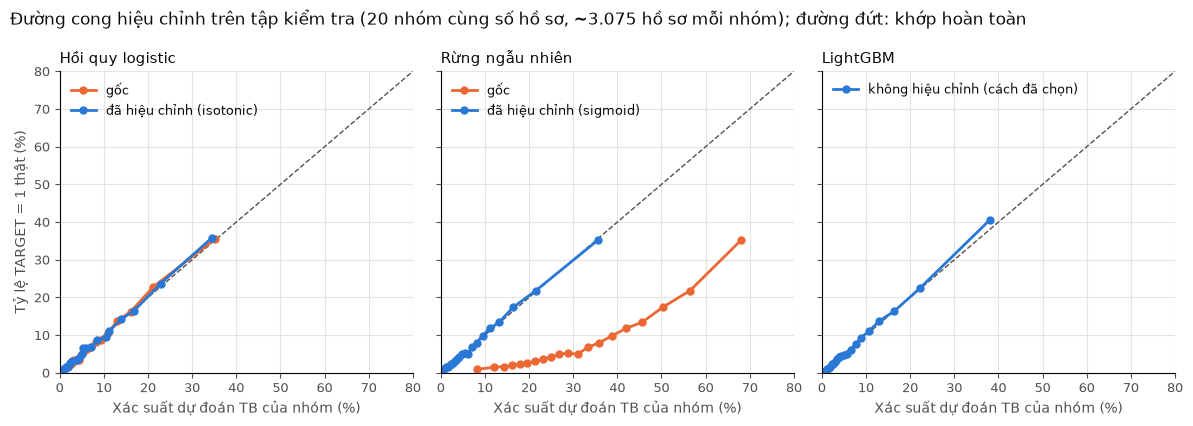

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4.3), sharey=True)
for p, m in zip(ax, MO_HINH):
    p.plot([0, 80], [0, 80], color=MUTED, lw=1, ls="--")
    duong = [(p_te[m], ORANGE, "gốc"), (q_te[m], BLUE, f"đã hiệu chỉnh ({hieu_chinh[m]['cach']})")]
    if hieu_chinh[m]["cach"] == "khong":
        duong = [(p_te[m], BLUE, "không hiệu chỉnh (cách đã chọn)")]
    for q, mau, nhan in duong:
        thuc, du = calibration_curve(y_te, q, n_bins=20, strategy="quantile")
        p.plot(du * 100, thuc * 100, color=mau, lw=2, marker="o", ms=5, label=nhan)
    p.set_xlim(0, 80)
    p.set_ylim(0, 80)
    p.set_title(TEN[m], color=INK, fontsize=11, loc="left")
    p.set_xlabel("Xác suất dự đoán TB của nhóm (%)", color=MUTED)
    p.grid(color=GRID, lw=0.8)
    p.set_axisbelow(True)
    p.tick_params(colors=MUTED, labelsize=9)
    p.spines[["top", "right"]].set_visible(False)
    p.legend(frameon=False, fontsize=9, loc="upper left", labelcolor=INK)
ax[0].set_ylabel("Tỷ lệ TARGET = 1 thật (%)", color=MUTED)
fig.suptitle("Đường cong hiệu chỉnh trên tập kiểm tra (20 nhóm cùng số hồ sơ, ~3.075 hồ sơ mỗi nhóm); đường đứt: khớp hoàn toàn",
             color=INK, fontsize=12, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "ml_test_hieu_chinh.png", dpi=150)

In [12]:
def dai(q):
    diem = np.round(q * 100, 1)
    return np.select([diem < 5, diem < 15], ["thấp (< 5%)", "trung bình (5% – < 15%)"], "cao (≥ 15%)")


KHOANG = {"thấp (< 5%)": (0, 0.05), "trung bình (5% – < 15%)": (0.05, 0.15), "cao (≥ 15%)": (0.15, 1)}
bang = []
for m in MO_HINH:
    for ten_dai, g in pd.DataFrame({"q": q_te[m], "y": y_te, "dai": dai(q_te[m])}).groupby("dai"):
        lo, hi = KHOANG[ten_dai]
        bang.append({"mô hình": m, "dải": ten_dai, "số hồ sơ": len(g), "tỷ lệ hồ sơ": len(g) / len(y_te), "điểm TB": g.q.mean(),
                     "tỷ lệ thật": g.y.mean(), "thật trong khoảng dải": lo <= g.y.mean() < hi})
pd.DataFrame(bang).set_index(["mô hình", "dải"]).loc[[(m, t) for m in MO_HINH for t in KHOANG]]

số hồ sơ  tỷ lệ hồ sơ  điểm TB  tỷ lệ thật  \
mô hình dải                                                                   
LR      thấp (< 5%)                 28432       0.4623   0.0253      0.0247   
        trung bình (5% – < 15%)     23700       0.3853   0.0826      0.0820   
        cao (≥ 15%)                  9371       0.1524   0.2418      0.2474   
RF      thấp (< 5%)                 30116       0.4897   0.0266      0.0264   
        trung bình (5% – < 15%)     22503       0.3659   0.0865      0.0861   
        cao (≥ 15%)                  8884       0.1444   0.2489      0.2514   
LGBM    thấp (< 5%)                 31967       0.5198   0.0256      0.0251   
        trung bình (5% – < 15%)     20703       0.3366   0.0855      0.0860   
        cao (≥ 15%)                  8833       0.1436   0.2606      0.2696   

                                 thật trong khoảng dải  
mô hình dải                                             
LR      thấp (< 5%)                               True  
        trung bình (5% – < 15%)                   True  
        cao (≥ 15%)                               True  
RF      thấp (< 5%)                               True  
        trung bình (5% – < 15%)                   True  
        cao (≥ 15%)                               True  
LGBM    thấp (< 5%)                               True  
        trung bình (5% – < 15%)                   True  
        cao (≥ 15%)                               True

## 7. F1 và ma trận nhầm lẫn tại ngưỡng B10

In [13]:
mt = []
for m in MO_HINH:
    du = q_te[m] >= nguong[m]
    tn, fp, fn, tp = confusion_matrix(y_te, du).ravel()
    mt.append({"mô hình": m, "ngưỡng": nguong[m], "F1": f1_score(y_te, du), "precision": tp / (tp + fp), "recall": tp / (tp + fn),
               "TN": tn, "FP": fp, "FN": fn, "TP": tp, "tỷ lệ báo nhầm (FPR)": fp / (fp + tn), "tỷ lệ đoán 1": du.mean()})
mt = pd.DataFrame(mt).set_index("mô hình")
mt

,ngưỡng,F1,precision,recall,TN,FP,FN,TP,tỷ lệ báo nhầm (FPR),tỷ lệ đoán 1
mô hình,,,,,,,,,,
LR,0.1592,0.3248,0.2667,0.4151,50872,5666,2904,2061,0.1002,0.1256
RF,0.1527,0.3235,0.2550,0.4423,50123,6415,2769,2196,0.1135,0.1400
LGBM,0.1544,0.3468,0.2752,0.4685,50413,6125,2639,2326,0.1083,0.1374


## 8. Đường ROC và precision–recall

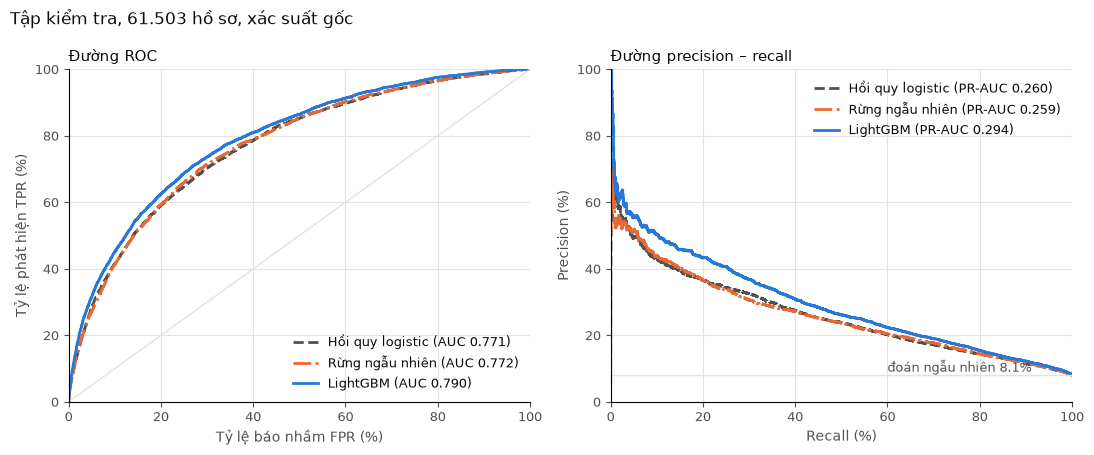

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for m, mau, ls in zip(MO_HINH, [MUTED, ORANGE, BLUE], ["--", "-.", "-"]):
    fpr, tpr, _ = roc_curve(y_te, p_te[m])
    ax[0].plot(fpr * 100, tpr * 100, color=mau, lw=2, ls=ls, label=f"{TEN[m]} (AUC {auc[m]:.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p_te[m])
    ax[1].plot(rc * 100, pr * 100, color=mau, lw=2, ls=ls, label=f"{TEN[m]} (PR-AUC {phan_biet.loc[m, 'PR-AUC']:.3f})")
ax[0].plot([0, 100], [0, 100], color=GRID, lw=1)
ax[1].axhline(y_te.mean() * 100, color=GRID, lw=1)
ax[1].text(60, y_te.mean() * 100 + 1, f"đoán ngẫu nhiên {y_te.mean():.1%}", color=MUTED, fontsize=9)
for p, tieu_de, x, yl in [(ax[0], "Đường ROC", "Tỷ lệ báo nhầm FPR (%)", "Tỷ lệ phát hiện TPR (%)"),
                          (ax[1], "Đường precision – recall", "Recall (%)", "Precision (%)")]:
    p.set_title(tieu_de, color=INK, fontsize=11, loc="left")
    p.set_xlabel(x, color=MUTED)
    p.set_ylabel(yl, color=MUTED)
    p.set_xlim(0, 100)
    p.set_ylim(0, 100)
    p.grid(color=GRID, lw=0.8)
    p.set_axisbelow(True)
    p.tick_params(colors=MUTED, labelsize=9)
    p.spines[["top", "right"]].set_visible(False)
    p.legend(frameon=False, fontsize=9, labelcolor=INK, loc="lower right" if p is ax[0] else "upper right")
fig.suptitle("Tập kiểm tra, 61.503 hồ sơ, xác suất gốc", color=INK, fontsize=12, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "ml_test_roc_pr.png", dpi=150)

## 9. Lưu mô hình được chọn

In [15]:
thu_muc = ROOT / "ml" / "models"
thu_muc.mkdir(exist_ok=True)
joblib.dump(cuoi[CHON], thu_muc / f"{CHON}.joblib")
lai = joblib.load(thu_muc / f"{CHON}.joblib")
Xp = lai[0].transform(X_te)
assert np.allclose(lai[-1].predict_proba(Xp.astype(np.float32) if CHON == "RF" else Xp)[:, 1], p_te[CHON])
print(f"Đã lưu ml/models/{CHON}.joblib ({(thu_muc / f'{CHON}.joblib').stat().st_size / 1e6:.1f} MB); nạp lại cho đúng dự đoán test")

Đã lưu ml/models/LGBM.joblib (6.9 MB); nạp lại cho đúng dự đoán test


## 10. Nhận xét (sau thực nghiệm)

- **Thứ tự:** LightGBM 0,7905 [0,7839; 0,7970] > RF 0,7721 > LR 0,7706. LightGBM hơn RF +0,0184 [+0,0156; +0,0212] và hơn LR +0,0199 [+0,0168; +0,0229]: "cải thiện".
  RF − LR +0,0015 [−0,0016; +0,0046]: "không đủ bằng chứng", dù ở CV RF hơn LR cả 5 fold (+0,002 … +0,004). Theo luật mục 1, **LightGBM** là mô hình cho B12, B13.
- **Không thấy lạc quan do chọn lựa:** AUC test cao hơn AUC CV ở cả ba mô hình (+0,0025 … +0,0047), cùng chiều, trong khi hiệu giữa hai mô hình gần như giữ nguyên (LGBM − LR: CV 0,0196, test 0,0199; LGBM − RF: 0,0163 → 0,0184).
  Mức tăng chung cho cả ba nên phần lớn đến từ mẫu kiểm tra (CI một mô hình rộng khoảng ±0,0066), một phần từ việc mô hình cuối học trên 100% train thay vì 80%.
- **Học thuộc:** LR không học thuộc (AUC train thấp hơn test). RF 0,998 trên dữ liệu đã học, LightGBM 0,877, nhưng AUC test vẫn ngang hoặc hơn CV nên khoảng cách train − test không làm giảm chất lượng trên hồ sơ mới.
- **Độ khớp giữ trên test:** chênh trung bình ≤ 0,12 điểm %, hệ số góc 1,009–1,038; mọi dải QĐ-26 của cả ba mô hình có tỷ lệ thật nằm trong khoảng dải. RF gốc lệch xa (TB 30,75%) và sigmoid học từ B9 sửa đúng trên dữ liệu mới.
- **F1 test** cao hơn F1 OOF B10 khoảng 0,005–0,011, cùng chiều với AUC; LightGBM 0,347 (precision 0,275, recall 0,469).